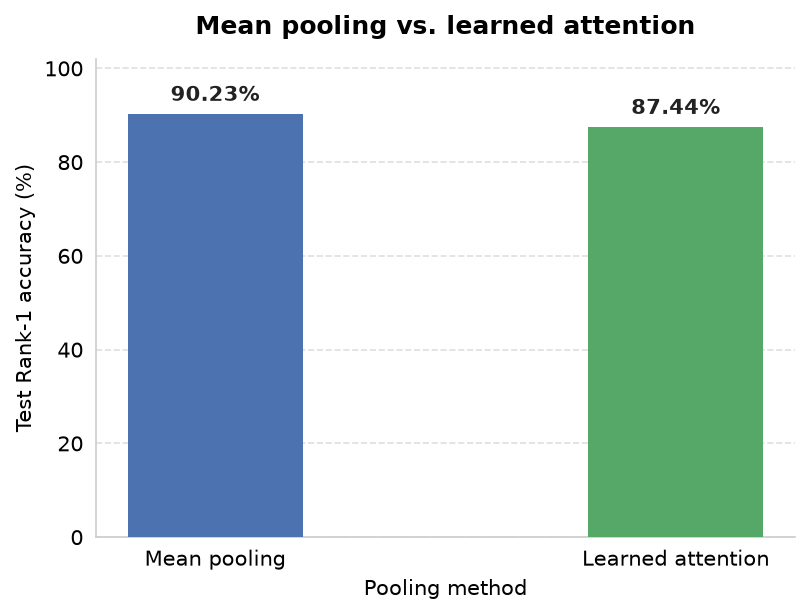

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

df = pd.read_csv("../results/test_attention_comparison.csv")

fig, ax = plt.subplots(figsize=(5.5, 4.2), dpi=150)
bars = ax.bar(df["method"], df["rank1_pct"], width=0.38, color=["#4C72B0", "#55A868"], zorder=3)

ax.bar_label(bars, fmt="%.2f%%", padding=4, fontsize=10, fontweight="bold", color="#222222")
ax.set(ylim=(0, 102), xlabel="Pooling method", ylabel="Test Rank-1 accuracy (%)")
ax.set_title("Mean pooling vs. learned attention", fontsize=12, fontweight="bold", pad=12)

ax.spines[["top", "right"]].set_visible(False)
ax.spines[["left", "bottom"]].set_color("#CCCCCC")
ax.tick_params(length=0, pad=6)
ax.yaxis.grid(True, linestyle="--", alpha=0.4, zorder=0)

plt.tight_layout()
plt.savefig("../results/test_attention_comparison.png", dpi=300)
plt.show()

In [2]:
import sys
import numpy as np
import seaborn as sns
import torch

from sklearn.metrics import confusion_matrix
from sklearn.manifold import TSNE

import os
os.chdir("..")
sys.path.insert(0, os.getcwd())

from core.core_objective import aggregate_video_embeddings
from core.evaluate_attention import load_model
from core.train_attention import load_video_features

embeddings_path = "data/polarbear_embeddings.npz"
best_weights = pd.read_csv("results/attention_comparison_runs.csv").sort_values("rank1_pct").iloc[-1]["weights"]
device = "cuda" if torch.cuda.is_available() else "cpu"

mean_embs, mean_df = aggregate_video_embeddings(embeddings_path)
feats, labels, vid_df = load_video_features(embeddings_path)

model = load_model(best_weights, feats.shape[-1], len(labels.unique()), device).eval()
with torch.no_grad():
    out = model(feats.to(device))
    attn_embs = (out[1] if isinstance(out, tuple) else out).cpu().numpy()

Attn Rank-1: 88.84% | Mean Rank-1: 90.70%


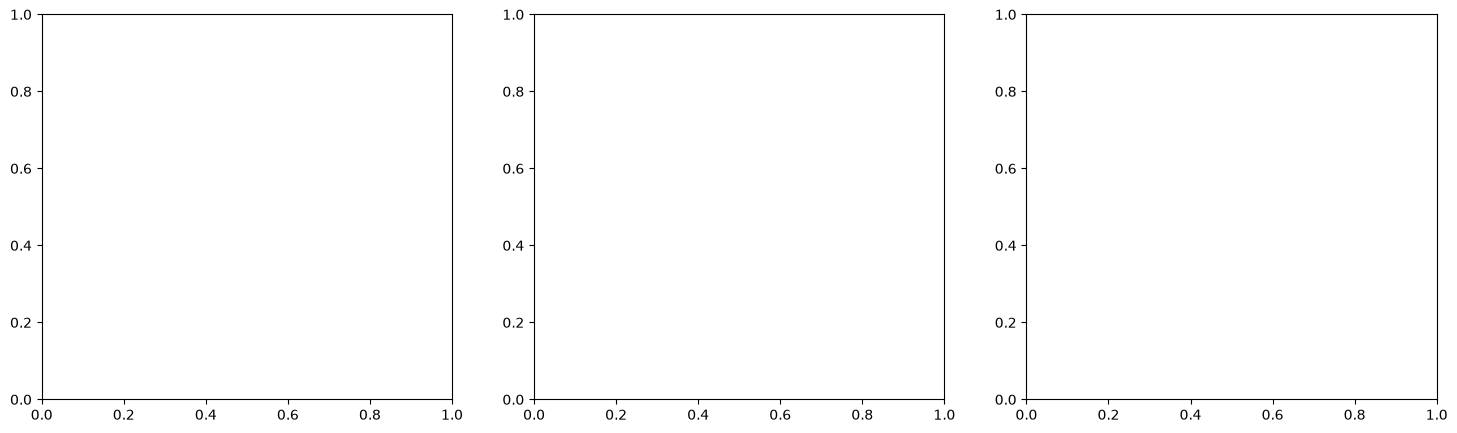

In [ ]:
ID_COL = "identity"
VID_COL = "sequence"

def get_matches(embs, df):
    norm_embs = embs / np.linalg.norm(embs, axis=1, keepdims=True)
    sim = norm_embs @ norm_embs.T
    np.fill_diagonal(sim, -np.inf)

    test_idx = np.where(df["split"] == "test")[0]
    ids = df[ID_COL].values
    rows = []

    for i in test_idx:
        ranked = np.argsort(-sim[i])
        top1 = ranked[0]
        true_id = ids[i]
        best_true_sim = sim[i, (ids == true_id) & (np.arange(len(ids)) != i)].max()

        rows.append({
            "video": df[VID_COL].iloc[i],
            "true_id": true_id,
            "pred_id": ids[top1],
            "matched_video": df[VID_COL].iloc[top1],
            "correct": true_id == ids[top1],
            "true_rank": int(np.where(ids[ranked] == true_id)[0][0] + 1),
            "top1_sim": round(float(sim[i, top1]), 4),
            "sim_gap": round(float(best_true_sim - sim[i, top1]), 4),
        })
    return pd.DataFrame(rows), sim

attn_df, attn_sim = get_matches(attn_embs, vid_df)
mean_df_res, _ = get_matches(mean_embs, mean_df)

print(f"Attn Rank-1: {attn_df['correct'].mean()*100:.2f}% | Mean Rank-1: {mean_df_res['correct'].mean()*100:.2f}%")

Row-normalized Confusion Matrix

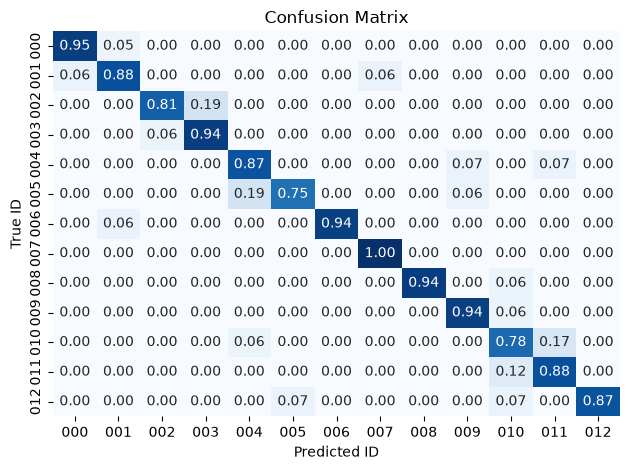

In [13]:
axes = plt.subplot()
classes = sorted(attn_df["true_id"].unique())
cm = confusion_matrix(attn_df["true_id"], attn_df["pred_id"], labels=classes, normalize="true")
sns.heatmap(cm, annot=True, fmt=".2f", cmap="Blues", xticklabels=classes, yticklabels=classes, ax=axes, cbar=False)
axes.set_title("Confusion Matrix")
axes.set_xlabel("Predicted ID")
axes.set_ylabel("True ID")
plt.tight_layout()
plt.show()

Genuine vs. Impostor Cosine Similarity

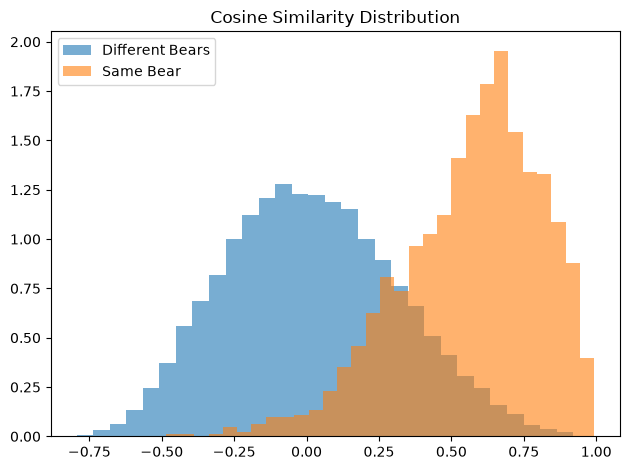

In [14]:
axes = plt.subplot()
test_idx = np.where(vid_df["split"] == "test")[0]
sub_sim = attn_sim[np.ix_(test_idx, test_idx)]
t_ids = vid_df[ID_COL].values[test_idx]
iu = np.triu_indices_from(sub_sim, k=1)
same = t_ids[iu[0]] == t_ids[iu[1]]

axes.hist(sub_sim[iu][~same], bins=30, alpha=0.6, density=True, label="Different Bears")
axes.hist(sub_sim[iu][same], bins=30, alpha=0.6, density=True, label="Same Bear")
axes.set_title("Cosine Similarity Distribution")
axes.legend()
plt.tight_layout()
plt.show()

CMC Curve (Rank 1 to 10)

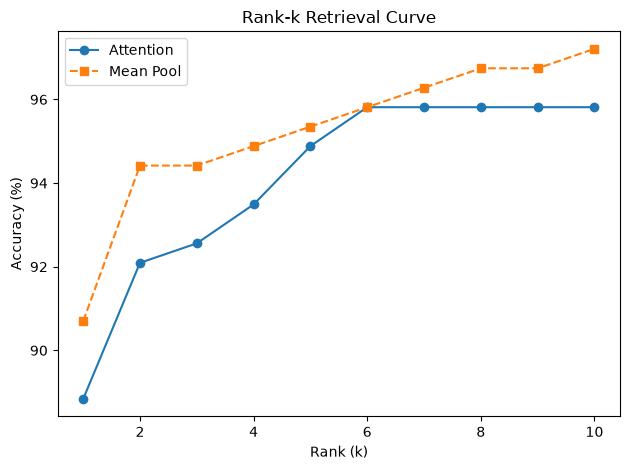

In [15]:
axes = plt.subplot()
ranks = np.arange(1, 11)
axes.plot(ranks, [(attn_df["true_rank"] <= k).mean() * 100 for k in ranks], marker="o", label="Attention")
axes.plot(ranks, [(mean_df_res["true_rank"] <= k).mean() * 100 for k in ranks], marker="s", linestyle="--", label="Mean Pool")
axes.set_title("Rank-k Retrieval Curve")
axes.set_xlabel("Rank (k)")
axes.set_ylabel("Accuracy (%)")
axes.legend()

plt.tight_layout()
plt.show()

Most confident wrong predictions

In [16]:
print("Worst False Positives:")
display(attn_df[~attn_df["correct"]].sort_values("sim_gap").head(10))

Worst False Positives:


,video,true_id,pred_id,matched_video,correct,true_rank,top1_sim,sim_gap
100,006C01T000,006,001,001C01T008,False,114,0.6711,-0.2758
84,005C01T037,005,004,004C01T065,False,193,0.7266,-0.2716
79,004C02T102,004,011,011C03T036,False,101,0.8440,-0.2482
34,001C03T081,001,000,000C02T029,False,111,0.9287,-0.1775
214,012C03T027,012,010,010C02T024,False,50,0.7838,-0.1661
181,010C02T110,010,004,004C01T016,False,22,0.7939,-0.1455
42,002C02T042,002,003,003C01T013,False,33,0.7671,-0.1381
53,003C01T032,003,002,002C01T094,False,127,0.9331,-0.1283
95,005C02T038,005,004,004C01T055,False,18,0.8524,-0.1096
5,000C02T014,000,001,001C03T094,False,6,0.8610,-0.0848


Where Attention hurt vs. Mean Pooling

In [17]:
merged = attn_df.merge(mean_df_res, on="video", suffixes=("_attn", "_mean"))
print("Attention Hurt (Mean got right, Attn missed):")
display(merged[~merged["correct_attn"] & merged["correct_mean"]][["video", "true_id_attn", "pred_id_attn", "pred_id_mean", "sim_gap_attn"]])

Attention Hurt (Mean got right, Attn missed):


,video,true_id_attn,pred_id_attn,pred_id_mean,sim_gap_attn
24,001C01T069,001,007,001,-0.0552
37,002C01T021,002,003,002,-0.0039
40,002C01T104,002,003,002,-0.0243
42,002C02T042,002,003,002,-0.1381
79,004C02T102,004,011,004,-0.2482
85,005C01T045,005,004,005,-0.0153
95,005C02T038,005,004,005,-0.1096
143,008C02T020,008,010,008,-0.0218
151,009C01T072,009,010,009,-0.0044
167,010C02T000,010,011,010,-0.0251


2D t-SNE of embeddings

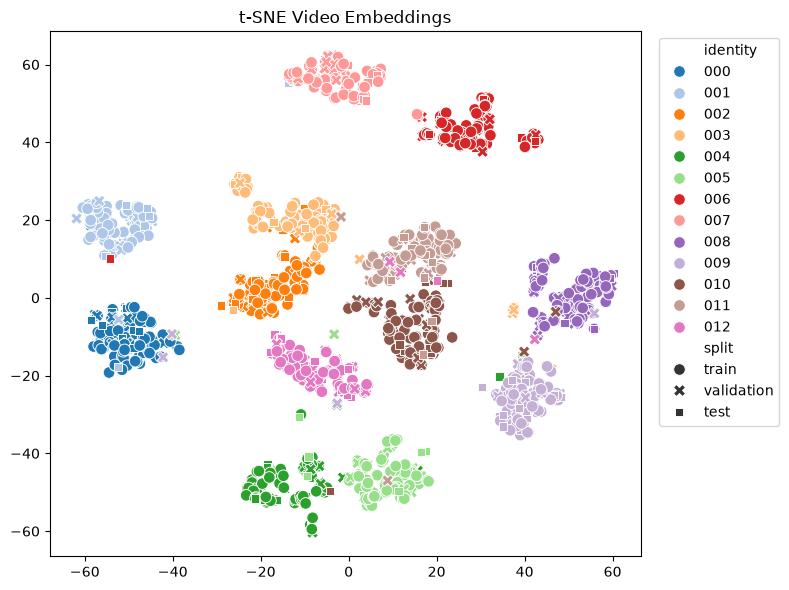

In [18]:
norm_attn = attn_embs / np.linalg.norm(attn_embs, axis=1, keepdims=True)
coords = TSNE(n_components=2, perplexity=15, metric="cosine", random_state=42).fit_transform(norm_attn)

plt.figure(figsize=(8, 6))
sns.scatterplot(x=coords[:, 0], y=coords[:, 1], hue=vid_df[ID_COL].astype(str), style=vid_df["split"], s=70, palette="tab20")
plt.title("t-SNE Video Embeddings")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()